In [1]:
import pandas as pd
import numpy as np 
import matplotlib.pyplot as plt
from sklearn.datasets import load_breast_cancer

In [5]:
df = pd.DataFrame(load_breast_cancer().data, columns=load_breast_cancer().feature_names)
df['target'] = load_breast_cancer().target
df.isnull().sum()

mean radius                0
mean texture               0
mean perimeter             0
mean area                  0
mean smoothness            0
mean compactness           0
mean concavity             0
mean concave points        0
mean symmetry              0
mean fractal dimension     0
radius error               0
texture error              0
perimeter error            0
area error                 0
smoothness error           0
compactness error          0
concavity error            0
concave points error       0
symmetry error             0
fractal dimension error    0
worst radius               0
worst texture              0
worst perimeter            0
worst area                 0
worst smoothness           0
worst compactness          0
worst concavity            0
worst concave points       0
worst symmetry             0
worst fractal dimension    0
target                     0
dtype: int64

In [6]:
df.dtypes

mean radius                float64
mean texture               float64
mean perimeter             float64
mean area                  float64
mean smoothness            float64
mean compactness           float64
mean concavity             float64
mean concave points        float64
mean symmetry              float64
mean fractal dimension     float64
radius error               float64
texture error              float64
perimeter error            float64
area error                 float64
smoothness error           float64
compactness error          float64
concavity error            float64
concave points error       float64
symmetry error             float64
fractal dimension error    float64
worst radius               float64
worst texture              float64
worst perimeter            float64
worst area                 float64
worst smoothness           float64
worst compactness          float64
worst concavity            float64
worst concave points       float64
worst symmetry      

In [32]:
x = df.drop(columns=['target'])
y = df[['target']]

In [39]:
from sklearn.preprocessing import StandardScaler
x = StandardScaler().fit_transform(x)
x

array([[ 1.09706398, -2.07333501,  1.26993369, ...,  2.29607613,
         2.75062224,  1.93701461],
       [ 1.82982061, -0.35363241,  1.68595471, ...,  1.0870843 ,
        -0.24388967,  0.28118999],
       [ 1.57988811,  0.45618695,  1.56650313, ...,  1.95500035,
         1.152255  ,  0.20139121],
       ...,
       [ 0.70228425,  2.0455738 ,  0.67267578, ...,  0.41406869,
        -1.10454895, -0.31840916],
       [ 1.83834103,  2.33645719,  1.98252415, ...,  2.28998549,
         1.91908301,  2.21963528],
       [-1.80840125,  1.22179204, -1.81438851, ..., -1.74506282,
        -0.04813821, -0.75120669]], shape=(569, 30))

In [40]:
from sklearn.model_selection import train_test_split
x_train, x_test, y_train, y_test = train_test_split(x, y, test_size=0.2,random_state=42)
x_train.shape, x_test.shape, y_train.shape, y_test.shape

((455, 30), (114, 30), (455, 1), (114, 1))

In [46]:
from sklearn import svm
from sklearn.metrics import accuracy_score, jaccard_score, f1_score
for i in ['sigmoid', 'poly', 'rbf', 'precomputed', 'linear']:
    try:
        model = svm.SVC(kernel=i)
        model.fit(x_train, y_train)
        predict = model.predict(x_test)
        ja = jaccard_score(y_test, predict, pos_label=1)
        f1 = f1_score(y_test, predict, average='weighted')
        acc = accuracy_score(y_test, predict)
        print("kernel: ",i,"\njaccard score: ",ja,"\nf1 score: ",f1,"\naccuracy score: ",acc,"\n")
    except Exception as e:
        print('error: ',e)

C:\Users\ZAHRA\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\utils\validation.py:1365: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples, ), for example using ravel().
  y = column_or_1d(y, warn=True)
C:\Users\ZAHRA\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\utils\validation.py:1365: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples, ), for example using ravel().
  y = column_or_1d(y, warn=True)
C:\Users\ZAHRA\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\utils\validation.py:1365: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples, ), for example using ravel().
  y = column_or_1d(y, warn=True)


kernel:  sigmoid 
jaccard score:  0.918918918918919 
f1 score:  0.9473684210526315 
accuracy score:  0.9473684210526315 

kernel:  poly 
jaccard score:  0.8255813953488372 
f1 score:  0.8608074865552686 
accuracy score:  0.868421052631579 

kernel:  rbf 
jaccard score:  0.958904109589041 
f1 score:  0.973621425014614 
accuracy score:  0.9736842105263158 

error:  Precomputed matrix must be a square matrix. Input is a 455x30 matrix.
kernel:  linear 
jaccard score:  0.9315068493150684 
f1 score:  0.9562368871555263 
accuracy score:  0.956140350877193 



C:\Users\ZAHRA\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\utils\validation.py:1365: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples, ), for example using ravel().
  y = column_or_1d(y, warn=True)
C:\Users\ZAHRA\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\utils\validation.py:1365: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples, ), for example using ravel().
  y = column_or_1d(y, warn=True)


In [47]:
model = svm.SVC(kernel='rbf')
model.fit(x_train, y_train)
predict = model.predict(x_test)

C:\Users\ZAHRA\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\utils\validation.py:1365: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples, ), for example using ravel().
  y = column_or_1d(y, warn=True)


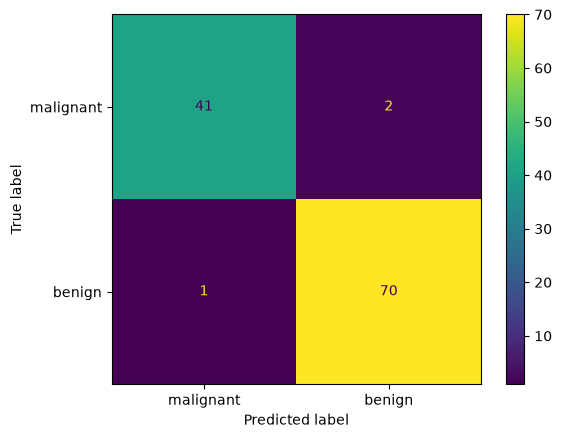

In [48]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
cm = confusion_matrix(y_test, predict)
display = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=load_breast_cancer().target_names)
display.plot()
plt.show()